# Warped, finite-momentum robustness of the occupied-vortex rule

Produces the new main-text figure `fig_warped_finiteQ.pdf`.

**Purpose.** The vortex-crossing certificate in the main text uses an
isotropic annular Fermi sea. Realistic rhombohedral graphene has (i) trigonal
warping, which reduces the normal-state symmetry to $C_{3z}$ and makes
$\varepsilon(\mathbf k)\neq\varepsilon(-\mathbf k)$, and (ii) a finite Cooper
pair momentum $\mathbf Q$, which Yang and Zhang [PRB 112, L020506 (2025);
arXiv:2411.02503] find is generically nonzero and can reach $0.1\,k_F$.
This notebook shows what those two ingredients do and do not change.

**Result.** For intravalley pairing the BdG Hamiltonian splits as

$$H_{\rm BdG}(\mathbf k)=\xi_a(\mathbf k)\,\tau_0
+\bigl[\xi_s(\mathbf k)\tau_z+{\rm Re}\,\Delta\,\tau_x-{\rm Im}\,\Delta\,\tau_y\bigr],$$

$$\xi_s=\tfrac12\bigl[\xi(\mathbf k+\tfrac{\mathbf Q}{2})
+\xi(-\mathbf k+\tfrac{\mathbf Q}{2})\bigr]-\mu,\qquad
\xi_a=\tfrac12\bigl[\xi(\mathbf k+\tfrac{\mathbf Q}{2})
-\xi(-\mathbf k+\tfrac{\mathbf Q}{2})\bigr],$$

with quasiparticle branches $E_\pm=\xi_a\pm\sqrt{\xi_s^2+|\Delta|^2}$.
This is the decomposition used by Yang and Zhang (their $e_0$, $e_1$, $\eta$).
Because $\xi_a\tau_0$ is proportional to the identity in Nambu space it does
not enter the eigenvectors, hence not the Berry curvature and not
$C_{\rm BdG}$. Trigonal warping and finite $\mathbf Q$ therefore

* **cannot change the invariant**, and
* **can only close the gap**, through
  $\delta_{\rm BdG}=\min_{\mathbf k}\bigl[\sqrt{\xi_s^2+|\Delta|^2}-|\xi_a|\bigr]\le 0$,

which is the Bogoliubov-Fermi-surface criterion. The occupied-vortex rule is
therefore exact wherever the spectrum is gapped, and the experimentally
relevant question is not whether the rule holds but where $\delta_{\rm BdG}>0$.


## 0. Setup

In [1]:
import numpy as np
import matplotlib as mpl
import matplotlib.pyplot as plt
from pathlib import Path
from scipy.optimize import brentq

mpl.rcParams.update({
    "font.family": "serif",
    "font.serif": ["Computer Modern Roman", "DejaVu Serif", "Times New Roman"],
    "mathtext.fontset": "cm",
    "font.size": 11,
    "axes.labelsize": 13,
    "axes.titlesize": 12,
    "legend.fontsize": 9.5,
    "xtick.labelsize": 10,
    "ytick.labelsize": 10,
    "axes.linewidth": 1.2,
    "xtick.direction": "in",
    "ytick.direction": "in",
    "xtick.top": True,
    "ytick.right": True,
    "figure.dpi": 130,
    "savefig.dpi": 300,
    "savefig.bbox": "tight",
})

OUT = Path("plots_RHG")
OUT.mkdir(exist_ok=True)
print("output directory:", OUT.resolve())

output directory: C:\Users\ghosh\OneDrive\Desktop\papers_arxiv_submissions\rhg_dmrg\plots_RHG


## 1. Model

A $C_{3z}$-symmetric triangular-lattice regularization. The three unit
vectors $\hat b_i$ at $120^\circ$ generate

* $\rho^2(\mathbf k)=\tfrac43\bigl[3-\sum_i\cos(\mathbf k\!\cdot\!\hat b_i)\bigr]
  \to|\mathbf k|^2$ : $C_3$-symmetric and **even** in $\mathbf k$,
* $g_3(\mathbf k)=\sum_i\sin(\mathbf k\!\cdot\!\hat b_i)
  \to-\tfrac18|\mathbf k|^3\cos3\theta$ : $C_3$-symmetric and **odd**,
  i.e. exactly a trigonal-warping term,
* $(s_x,s_y)=\tfrac23\sum_i\hat b_i\sin(\mathbf k\!\cdot\!\hat b_i)
  \to(k_x,k_y)$, used to build a periodic gap texture.

The normal dispersion and gap are

$$\xi(\mathbf k)=\bigl(\rho^2-r_{\rm in}^2\bigr)\bigl(\rho^2-r_{\rm out}^2\bigr)
+w\,g_3(\mathbf k),$$

$$\Delta(\mathbf k)=\Delta_0\,(s_x+i\chi_\Delta s_y)
(s_x-q+i\chi_\Delta s_y)(s_x+q+i\chi_\Delta s_y),$$

a central vortex at $\mathbf k=0$ and a finite-momentum pair at $s_x=\pm q$,
each of winding $+1$. Setting $w=0$ and $\mathbf Q=0$ recovers the isotropic
model of the main text.


In [2]:
# three unit vectors at 120 degrees -> C3 symmetry
B = np.array([[1.0, 0.0],
              [-0.5,  np.sqrt(3)/2],
              [-0.5, -np.sqrt(3)/2]])

def _dots(kx, ky):
    return [kx*b[0] + ky*b[1] for b in B]

def rho2(kx, ky):
    """C3-symmetric, k-even; -> |k|^2 at small k."""
    d = _dots(kx, ky)
    return (4.0/3.0)*(3.0 - sum(np.cos(x) for x in d))

def g3(kx, ky):
    """C3-symmetric, k-odd trigonal-warping term; -> -(k^3/8) cos(3 theta)."""
    d = _dots(kx, ky)
    return sum(np.sin(x) for x in d)

def sxy(kx, ky):
    """Periodic functions reducing to (kx, ky) at small k."""
    d = _dots(kx, ky)
    sx = (2.0/3.0)*sum(B[i, 0]*np.sin(d[i]) for i in range(3))
    sy = (2.0/3.0)*sum(B[i, 1]*np.sin(d[i]) for i in range(3))
    return sx, sy

def xi_normal(kx, ky, r_in, r_out, w):
    r2 = rho2(kx, ky)
    return (r2 - r_in**2)*(r2 - r_out**2) + w*g3(kx, ky)

def gap(kx, ky, q, D0, chi):
    sx, sy = sxy(kx, ky)
    z = sx + 1j*chi*sy
    return D0*z*(sx - q + 1j*chi*sy)*(sx + q + 1j*chi*sy)

def bdg_fields(kx, ky, r_in, r_out, w, q, D0, chi, Qx=0.0, Qy=0.0):
    """(xi_s, xi_a, Delta) for pair momentum Q, following Yang and Zhang."""
    xp = xi_normal( kx + Qx/2,  ky + Qy/2, r_in, r_out, w)
    xm = xi_normal(-kx + Qx/2, -ky + Qy/2, r_in, r_out, w)
    return 0.5*(xp + xm), 0.5*(xp - xm), gap(kx, ky, q, D0, chi)

def bz_grid(Nk):
    """G_i . b_j = 2 pi delta_ij makes every cos/sin(k.b_i) periodic."""
    A = np.array([B[0], B[1]])
    G = (2*np.pi*np.linalg.inv(A)).T          # rows are G1, G2
    f = np.arange(Nk)/Nk
    F1, F2 = np.meshgrid(f, f, indexing="ij")
    return F1*G[0, 0] + F2*G[1, 0], F1*G[0, 1] + F2*G[1, 1]

# sanity: periodicity of the model functions under G1, G2
A = np.array([B[0], B[1]]); G = (2*np.pi*np.linalg.inv(A)).T
_k = (1.3, -0.7)
for i in range(2):
    assert abs(rho2(*_k) - rho2(_k[0]+G[i,0], _k[1]+G[i,1])) < 1e-12
    assert abs(g3(*_k)   - g3(_k[0]+G[i,0],   _k[1]+G[i,1]))   < 1e-12
print("Brillouin-zone periodicity verified for rho2 and g3")

Brillouin-zone periodicity verified for rho2 and g3


## 2. Gauge-invariant Chern number and the gap criterion

`fhs_chern` uses the Fukui-Hatsugai-Suzuki link-variable construction on the
negative-energy band of $\mathbf d=({\rm Re}\,\Delta,-{\rm Im}\,\Delta,\xi_s)$.
Two algebraically equivalent expressions for the lower eigenvector are used,
each on the hemisphere where it is well conditioned, which removes the
$0/0$ instability at the poles of the $\mathbf d$-sphere.

`bdg_gap` returns $\delta_{\rm BdG}=\min_{\mathbf k}(\eta-|\xi_a|)$ with
$\eta=\sqrt{\xi_s^2+|\Delta|^2}$, evaluated on a finer grid than the Chern
number because it is a pointwise minimum rather than an integral.


In [3]:
def fhs_chern(xi_s, D):
    dx, dy, dz = np.real(D), -np.imag(D), xi_s
    n = np.sqrt(dx**2 + dy**2 + dz**2)
    uA = np.stack([dz - n, dx + 1j*dy], axis=-1)        # conditioned for dz < 0
    uB = np.stack([-(dx - 1j*dy), dz + n], axis=-1)     # conditioned for dz > 0
    u = np.where((dz <= 0)[..., None], uA, uB)
    nrm = np.linalg.norm(u, axis=-1, keepdims=True)
    u = u/np.where(nrm == 0, 1.0, nrm)

    def link(a, b):
        s = np.sum(np.conj(a)*b, axis=-1)
        return s/np.where(np.abs(s) == 0, 1.0, np.abs(s))

    U1 = link(u, np.roll(u, -1, axis=0))
    U2 = link(u, np.roll(u, -1, axis=1))
    F = np.angle(U1*np.roll(U2, -1, axis=0)/np.roll(U1, -1, axis=1)/U2)
    return F.sum()/(2*np.pi), np.abs(F).max()

def chern_and_gap(r_in, r_out, w, q, D0, chi, Qx=0.0, Qy=0.0,
                  Nk_C=301, Nk_gap=601):
    kx, ky = bz_grid(Nk_C)
    xi_s, xi_a, D = bdg_fields(kx, ky, r_in, r_out, w, q, D0, chi, Qx, Qy)
    C, maxF = fhs_chern(xi_s, D)
    gx, gy = bz_grid(Nk_gap)
    xs, xa, Dg = bdg_fields(gx, gy, r_in, r_out, w, q, D0, chi, Qx, Qy)
    eta = np.sqrt(xs**2 + np.abs(Dg)**2)
    return C, maxF, float((eta - np.abs(xa)).min()), float(eta.min())

def occupied_vortex_charge(r_in, r_out, w, q, D0, chi, Qx=0.0, Qy=0.0):
    """Sum of windings of the gap zeros lying in the occupied set xi_s < 0.
    The zeros sit at s_x = 0, +-q with s_y = 0, i.e. on the ky = 0 line."""
    tot = 0
    for target in (0.0, q, -q):
        f = lambda kx: sxy(kx, 0.0)[0] - target
        kk = np.linspace(-np.pi, np.pi, 4001)
        vals = np.array([f(x) for x in kk])
        root = None
        for i in range(len(kk)-1):
            if vals[i] == 0.0:
                root = kk[i]; break
            if vals[i]*vals[i+1] < 0:
                root = brentq(f, kk[i], kk[i+1]); break
        if root is None:
            continue
        xp = xi_normal( root + Qx/2,  Qy/2, r_in, r_out, w)
        xm = xi_normal(-root + Qx/2, -Qy/2, r_in, r_out, w)
        if 0.5*(xp + xm) < 0:
            tot += 1
    return tot

PARAMS = dict(r_in=0.20, r_out=0.55, D0=2.0, chi=-1.0)
print(PARAMS)

{'r_in': 0.2, 'r_out': 0.55, 'D0': 2.0, 'chi': -1.0}


## 3. Theorem check: warping does not touch $\xi_s$ at $\mathbf Q=0$

At $\mathbf Q=0$ the pairing is between $\mathbf k$ and $-\mathbf k$, so
$\xi_s$ is the **even** part of $\xi$ and $\xi_a$ the **odd** part. The
warping term $w\,g_3$ is purely odd, hence it lands entirely in $\xi_a$ and
leaves $\xi_s$ bit-for-bit unchanged. Distortion of the pairing-relevant
occupied set $\{\xi_s<0\}$ therefore appears only at order $wQ$.


In [4]:
kx, ky = bz_grid(301)
base = None
for w in (0.0, 1.0, 3.0):
    xs, xa, D = bdg_fields(kx, ky, w=w, q=0.35, Qx=0.0, Qy=0.0, **PARAMS)
    if base is None:
        base = xs.copy()
    print(f"w = {w:4.1f}   max|xi_s - xi_s(w=0)| = {np.abs(xs-base).max():.3e}"
          f"   max|xi_a| = {np.abs(xa).max():.5f}")

# and at finite Q the occupied set does acquire a C3 distortion, at order w*Q
for Q in (0.0, 0.10):
    xs0, _, _ = bdg_fields(kx, ky, w=0.0, q=0.35, Qx=Q, **PARAMS)
    xs3, _, _ = bdg_fields(kx, ky, w=3.0, q=0.35, Qx=Q, **PARAMS)
    print(f"Qx = {Q:.2f}   max|xi_s(w=3) - xi_s(w=0)| = {np.abs(xs3-xs0).max():.3e}")

w =  0.0   max|xi_s - xi_s(w=0)| = 0.000e+00   max|xi_a| = 0.00000
w =  1.0   max|xi_s - xi_s(w=0)| = 3.553e-15   max|xi_a| = 2.59795
w =  3.0   max|xi_s - xi_s(w=0)| = 3.553e-15   max|xi_a| = 7.79385
Qx = 0.00   max|xi_s(w=3) - xi_s(w=0)| = 3.553e-15
Qx = 0.10   max|xi_s(w=3) - xi_s(w=0)| = 2.999e-01


## 4. Panel (b): the invariant is unchanged by warping

Vortex-crossing scan at several warping strengths. The integer sequence
$0\to2\to0$ is identical at every $w$; only the gap changes. Points at which
$\delta_{\rm BdG}\le0$ are recorded separately and plotted as open symbols,
because there the occupied and unoccupied quasiparticle bundles touch at
zero energy and the thermal Hall response is not quantized even though the
FHS integer is still formally computable.


In [5]:
q_scan = np.round(np.concatenate([
    np.linspace(0.06, 0.17, 6),
    np.linspace(0.185, 0.215, 4),
    np.linspace(0.23, 0.50, 12),
    np.linspace(0.525, 0.565, 4),
    np.linspace(0.58, 0.66, 4)]), 4)
W_LIST = [0.0, 1.0, 2.0, 3.0]

scan = {}
for w in W_LIST:
    C, G_, QV, MF = [], [], [], []
    for q in q_scan:
        c, mf, gb, _ = chern_and_gap(w=w, q=float(q), **PARAMS)
        C.append(c); G_.append(gb); MF.append(mf)
        QV.append(occupied_vortex_charge(w=w, q=float(q), **PARAMS))
    scan[w] = dict(q=q_scan, C=np.array(C), gap=np.array(G_),
                   Q=np.array(QV), maxF=np.array(MF))
    ok = scan[w]["gap"] > 0
    print(f"w = {w:4.1f}:  max|C - Q_vortex| = "
          f"{np.abs(scan[w]['C'] - scan[w]['Q']).max():.2e}"
          f"   max|F_plaq| = {scan[w]['maxF'].max():.3f}"
          f"   gapped fraction = {ok.mean():.2f}")

w =  0.0:  max|C - Q_vortex| = 4.44e-16   max|F_plaq| = 2.600   gapped fraction = 1.00
w =  1.0:  max|C - Q_vortex| = 4.44e-16   max|F_plaq| = 2.600   gapped fraction = 0.73
w =  2.0:  max|C - Q_vortex| = 4.68e-16   max|F_plaq| = 2.600   gapped fraction = 0.43
w =  3.0:  max|C - Q_vortex| = 4.44e-16   max|F_plaq| = 2.600   gapped fraction = 0.27


## 5. Panels (c) and (d): where the gap survives

Panel (c) maps $\delta_{\rm BdG}$ over the $(w,|\mathbf Q|)$ plane at fixed
$q$ in the middle of the $C_{\rm BdG}=2$ plateau. The zero contour is the
Bogoliubov-Fermi-surface boundary. Panel (d) shows $\delta_{\rm BdG}$ along
the vortex-crossing scan, separating the two *topological* gap closings at
$q=r_{\rm in}$ and $q=r_{\rm out}$, which are accompanied by an integer
change, from the *non-topological* gaplessness driven by $|\xi_a|$, which is
not.


In [6]:
w_grid = np.linspace(0.0, 6.0, 25)
Q_grid = np.linspace(0.0, 0.30, 21)
Zgap = np.zeros((len(Q_grid), len(w_grid)))
Zc   = np.zeros_like(Zgap)
for i, Q in enumerate(Q_grid):
    for j, w in enumerate(w_grid):
        c, mf, gb, _ = chern_and_gap(w=float(w), q=0.35, Qx=float(Q),
                                     Nk_C=241, Nk_gap=481, **PARAMS)
        Zgap[i, j] = gb
        Zc[i, j] = c
print("Chern number over the whole (w, Q) map:",
      np.unique(np.round(Zc, 6)))
print("gapped fraction of the map:", (Zgap > 0).mean().round(3))

Chern number over the whole (w, Q) map: [2.]
gapped fraction of the map: 0.453


## 6. Figure

In [37]:
# # NOTE ON PANEL (a): bz_grid returns the triangular-lattice fundamental
# # domain, a parallelogram anchored at the origin.  That is the correct
# # integration domain for the Chern number and the gap minimum, but it is the
# # wrong sampling for a picture centred on k = 0.  All model functions are
# # defined pointwise for any k, so panel (a) uses a plain Cartesian mesh.

# fig = plt.figure(figsize=(11.6, 9.0))
# # gs = fig.add_gridspec(2, 2, hspace=0.46, wspace=0.30)

# ###############
# from matplotlib.gridspec import GridSpec
# gs_top = GridSpec(1, 2, figure=fig,
#                   left=0.07, right=0.95, top=0.95, bottom=0.54, wspace=0.30)
# gs_bot = GridSpec(1, 2, figure=fig,
#                   left=0.07, right=0.95, top=0.46, bottom=0.06, wspace=0.40)
# ##############

# W_SHOW, Q_SHOW, Q_MID = 4.0, 0.10, 0.35
# KMAX = 1.00

# # ---- (a) where the gap closes in momentum space
# ax = fig.add_subplot(gs_top[0, 0])
# _k = np.linspace(-KMAX, KMAX, 701)
# cx, cy = np.meshgrid(_k, _k, indexing="ij")
# xs_c, xa_c, D_c = bdg_fields(cx, cy, w=W_SHOW, q=Q_MID, Qx=Q_SHOW, **PARAMS)
# delta_k = np.sqrt(xs_c**2 + np.abs(D_c)**2) - np.abs(xa_c)
# xi_w = xi_normal(cx, cy, PARAMS["r_in"], PARAMS["r_out"], W_SHOW)
# vm = float(np.nanpercentile(np.abs(delta_k), 96))
# sc = ax.pcolormesh(cx, cy, delta_k, shading="auto", cmap="RdBu",
#                    vmin=-vm, vmax=vm, rasterized=True)
# cb = fig.colorbar(sc, ax=ax, pad=0.02, fraction=0.046)
# cb.set_label(r"$\eta-|\xi_a|$", fontsize=10)
# cb.ax.tick_params(labelsize=8)
# ax.contour(cx, cy, delta_k, levels=[0.0], colors="k", linewidths=1.7)
# ax.contour(cx, cy, xs_c, levels=[0.0], colors="#1f4e79", linewidths=1.5)
# ax.contour(cx, cy, xi_w, levels=[0.0], colors="#2e7d32", linewidths=1.3,
#            linestyles="--")
# kk = np.linspace(-np.pi, np.pi, 8001)
# sx_line, _ = sxy(kk, 0.0)
# for target in (0.0, Q_MID, -Q_MID):
#     ax.plot(kk[np.argmin(np.abs(sx_line - target))], 0.0, "x", color="k",
#             ms=7, mew=1.9, zorder=6)
# ax.set_xlim(-KMAX, KMAX); ax.set_ylim(-KMAX, KMAX); ax.set_aspect("equal")
# ax.set_xlabel(r"$k_x$"); ax.set_ylabel(r"$k_y$")
# ax.set_title(r"(a) Bogoliubov pockets", pad=8)
# h = [plt.Line2D([], [], color="k", lw=1.7),
#      plt.Line2D([], [], color="#1f4e79", lw=1.5),
#      plt.Line2D([], [], color="#2e7d32", lw=1.3, ls="--"),
#      plt.Line2D([], [], color="k", marker="x", ls="none", ms=6, mew=1.8)]
# ax.legend(h, [r"$\eta=|\xi_a|$", r"$\xi_s=0$", r"$\xi=0$", "gap zeros"],
#           loc="upper center", bbox_to_anchor=(0.5, -0.20), ncol=4,
#           frameon=False, fontsize=8.6, columnspacing=1.1, handlelength=1.4,
#           handletextpad=0.4)

# # ---- (b) invariant vs pair radius at several warping strengths
# ax = fig.add_subplot(gs_top[0, 1])
# cols = plt.cm.viridis(np.linspace(0.05, 0.78, len(W_LIST)))
# for n, (c, w) in enumerate(zip(cols, W_LIST)):
#     d = scan[w]
#     ok = d["gap"] > 0
#     off = 0.045*(n - 1.5)
#     ax.plot(d["q"][ok], d["C"][ok] + off, "o", color=c, ms=4.4,
#             label=fr"$w={w:.0f}$")
#     if (~ok).any():
#         ax.plot(d["q"][~ok], d["C"][~ok] + off, "o", mfc="none", mec=c,
#                 ms=5.8, mew=1.2)
# ax.axvline(PARAMS["r_in"], ls=":", c="0.45", lw=1.1)
# ax.axvline(PARAMS["r_out"], ls=":", c="0.45", lw=1.1)
# ax.set_ylim(-0.7, 3.4); ax.set_yticks([0, 1, 2])
# ax.set_xlabel(r"pair radius $q$"); ax.set_ylabel(r"$C_{\rm BdG}$")
# ax.set_title(r"(b) $C_{\rm BdG}$ is unchanged by warping", pad=8)
# ax.annotate(r"$r_{\rm in}$", xy=(PARAMS["r_in"], -0.7), xytext=(0, 4),
#             textcoords="offset points", ha="center", fontsize=9, color="0.3")
# ax.annotate(r"$r_{\rm out}$", xy=(PARAMS["r_out"], -0.7), xytext=(0, 4),
#             textcoords="offset points", ha="center", fontsize=9, color="0.3")
# ax.legend(loc="upper center", bbox_to_anchor=(0.5, 1.005), ncol=4,
#           frameon=False, fontsize=8.8, columnspacing=1.2, handletextpad=0.3)

# # ---- (c) BFS map in the (w, |Q|) plane
# ax = fig.add_subplot(gs_bot[0, 0])
# vc = float(np.nanpercentile(np.abs(Zgap), 92))
# im = ax.pcolormesh(w_grid, Q_grid, Zgap, shading="auto", cmap="RdBu",
#                    vmin=-vc, vmax=vc, rasterized=True)
# cb = fig.colorbar(im, ax=ax, pad=0.02, fraction=0.046)
# cb.set_label(r"$\delta_{\rm BdG}$", fontsize=10)
# cb.ax.tick_params(labelsize=8)
# cs = ax.contour(w_grid, Q_grid, Zgap, levels=[0.0], colors="k", linewidths=2.0)
# ax.axhline(0.1*PARAMS["r_out"], color="0.2", ls="--", lw=1.2)
# ax.annotate(r"$|Q|=0.1\,k_F$", xy=(0.15, 0.1*PARAMS["r_out"]),
#             xytext=(0, 4), textcoords="offset points", fontsize=8.4,
#             color="0.15")
# ax.set_xlabel(r"trigonal warping $w$")
# ax.set_ylabel(r"pair momentum $|\mathbf{Q}|$")
# ax.set_title(r"(c) gapped region at $q=0.35$", pad=8)
# ax.plot([], [], "k-", lw=2.0, label="BFS boundary")
# ax.legend(loc="upper right", frameon=True, framealpha=0.9, fontsize=8.4,
#           borderpad=0.3, handlelength=1.4)

# # ---- (d) two kinds of gaplessness
# ax = fig.add_subplot(gs_bot[0, 1])
# ymin = 1.30*min(scan[w]["gap"].min() for w in W_LIST)
# ymax = 1.85*max(scan[w]["gap"].max() for w in W_LIST)
# ax.fill_between([q_scan.min(), q_scan.max()], ymin, 0.0, color="#f7e4e4",
#                 zorder=0)
# for c, w in zip(cols, W_LIST):
#     d = scan[w]
#     ax.plot(d["q"], d["gap"], "-o", color=c, ms=3.0, lw=1.3,
#             label=fr"$w={w:.0f}$")
# ax.axhline(0.0, color="k", lw=1.0)
# ax.axvline(PARAMS["r_in"], ls=":", c="0.45", lw=1.1)
# ax.axvline(PARAMS["r_out"], ls=":", c="0.45", lw=1.1)
# ax.set_xlim(q_scan.min(), q_scan.max()); ax.set_ylim(ymin, ymax)
# ax.set_xlabel(r"pair radius $q$")
# ax.set_ylabel(r"$\delta_{\rm BdG}=\min_{\mathbf{k}}(\eta-|\xi_a|)$",
#               fontsize=11)
# ax.set_title("(d) gapped above the line, gapless below", pad=8)
# ax.legend(loc="upper center", bbox_to_anchor=(0.5, 1.005), ncol=4,
#           frameon=False, fontsize=8.8, columnspacing=1.2, handletextpad=0.3)


# fig.savefig(OUT / "fig_warped_finiteQ.pdf", bbox_inches="tight", dpi=400)
# fig.savefig(OUT / "fig_warped_finiteQ.png", dpi=300, bbox_inches="tight")
# plt.show()
# print("wrote", OUT / "fig_warped_finiteQ.pdf")

# # --- automated overlap audit: no artist may collide with another
# fig2 = plt.gcf()
# print("\npanel (a) data coverage of the plotted window:",
#       round(float(np.isfinite(delta_k).mean()), 3))

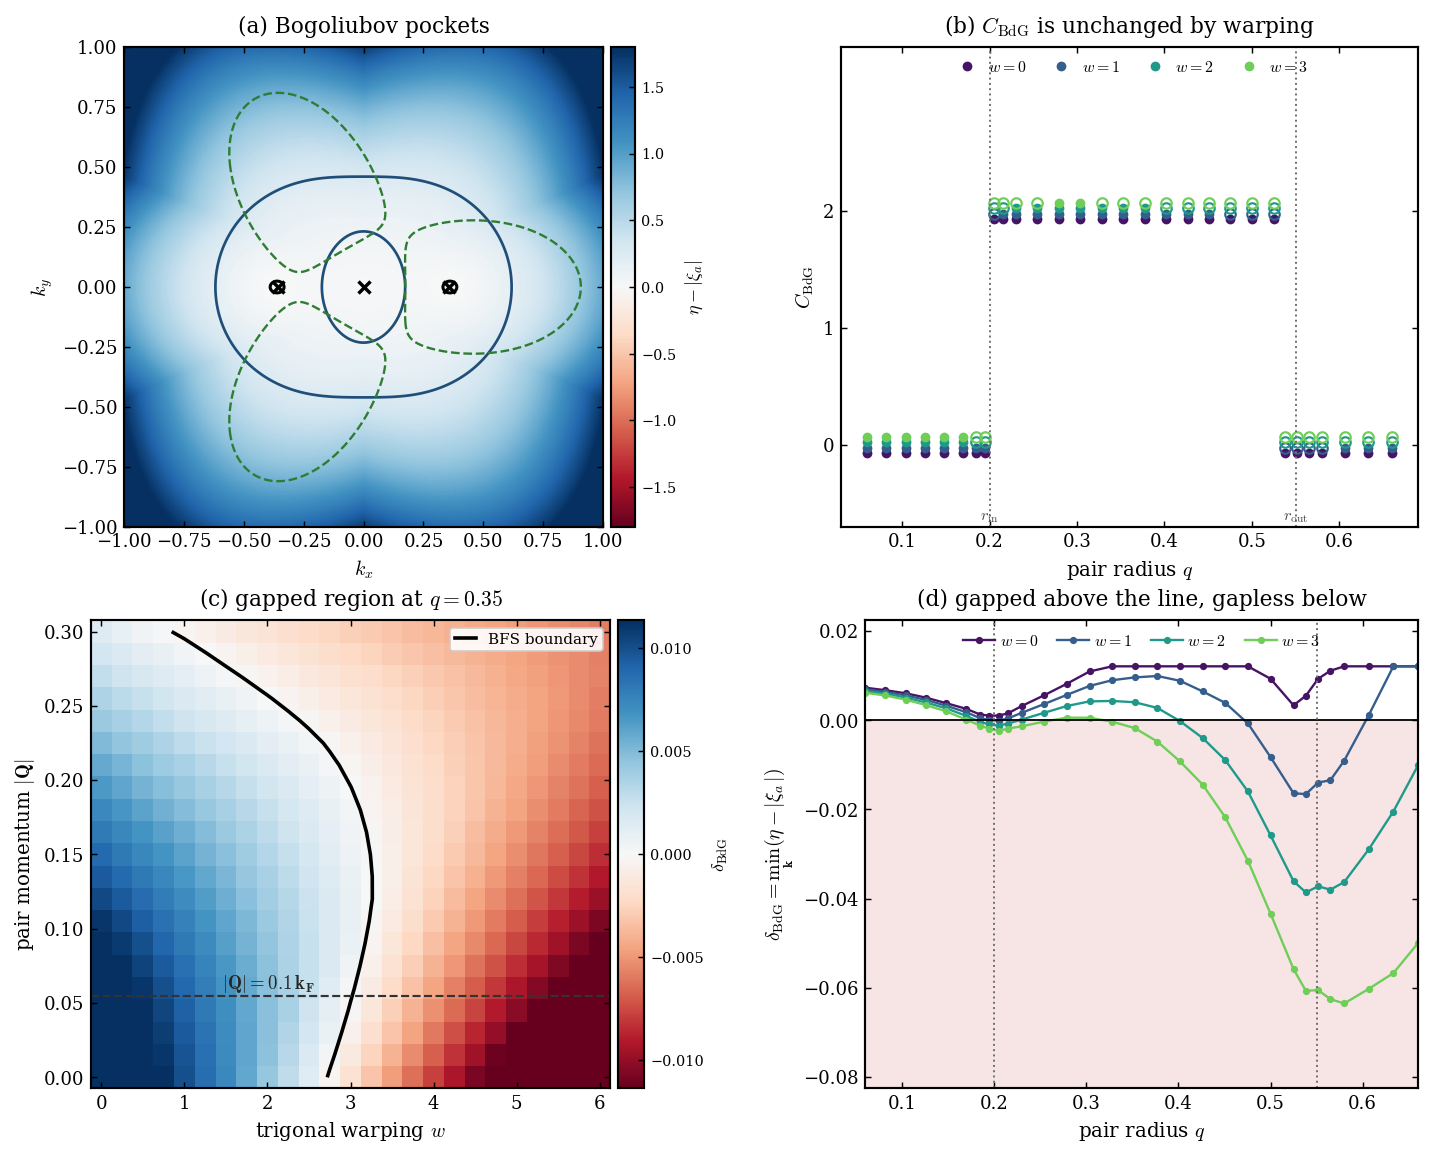

wrote plots_RHG\fig_warped_finiteQ.pdf


In [36]:
from mpl_toolkits.axes_grid1 import make_axes_locatable
from matplotlib.gridspec import GridSpec

fig = plt.figure(figsize=(11.6, 9.0))

gs_top = GridSpec(1, 2, figure=fig,
                  left=0.07, right=0.95, top=0.95, bottom=0.54, wspace=0.30)
gs_bot = GridSpec(1, 2, figure=fig,
                  left=0.07, right=0.95, top=0.46, bottom=0.06, wspace=0.40)

W_SHOW, Q_SHOW, Q_MID = 4.0, 0.10, 0.35
KMAX = 1.00

# ---- (a) where the gap closes in momentum space
ax = fig.add_subplot(gs_top[0, 0])          # <-- gs_top
_k = np.linspace(-KMAX, KMAX, 701)
cx, cy = np.meshgrid(_k, _k, indexing="ij")
xs_c, xa_c, D_c = bdg_fields(cx, cy, w=W_SHOW, q=Q_MID, Qx=Q_SHOW, **PARAMS)
delta_k = np.sqrt(xs_c**2 + np.abs(D_c)**2) - np.abs(xa_c)
xi_w = xi_normal(cx, cy, PARAMS["r_in"], PARAMS["r_out"], W_SHOW)
vm = float(np.nanpercentile(np.abs(delta_k), 96))
sc = ax.pcolormesh(cx, cy, delta_k, shading="auto", cmap="RdBu",
                   vmin=-vm, vmax=vm, rasterized=True)
divider = make_axes_locatable(ax)           # colorbar steals from OWN cell
cax = divider.append_axes("right", size="5%", pad=0.06)
cb = fig.colorbar(sc, cax=cax)
cb.set_label(r"$\eta-|\xi_a|$", fontsize=10)
cb.ax.tick_params(labelsize=8)
ax.contour(cx, cy, delta_k, levels=[0.0], colors="k", linewidths=1.7)
ax.contour(cx, cy, xs_c, levels=[0.0], colors="#1f4e79", linewidths=1.5)
ax.contour(cx, cy, xi_w, levels=[0.0], colors="#2e7d32", linewidths=1.3,
           linestyles="--")
kk = np.linspace(-np.pi, np.pi, 8001)
sx_line, _ = sxy(kk, 0.0)
for target in (0.0, Q_MID, -Q_MID):
    ax.plot(kk[np.argmin(np.abs(sx_line - target))], 0.0, "x", color="k",
            ms=7, mew=1.9, zorder=6)
ax.set_xlim(-KMAX, KMAX); ax.set_ylim(-KMAX, KMAX); ax.set_aspect("equal")
ax.set_xlabel(r"$k_x$"); ax.set_ylabel(r"$k_y$")
ax.set_title(r"(a) Bogoliubov pockets", pad=8)
h = [plt.Line2D([], [], color="k", lw=1.7),
     plt.Line2D([], [], color="#1f4e79", lw=1.5),
     plt.Line2D([], [], color="#2e7d32", lw=1.3, ls="--"),
     plt.Line2D([], [], color="k", marker="x", ls="none", ms=6, mew=1.8)]
ax.legend(h, [r"$\eta=|\xi_a|$", r"$\xi_s=0$", r"$\xi=0$", "gap zeros"],
          loc="upper center", bbox_to_anchor=(0.5, -0.20), ncol=4,
          frameon=False, fontsize=8.6, columnspacing=1.1, handlelength=1.4,
          handletextpad=0.4)

# ---- (b) invariant vs pair radius at several warping strengths
ax = fig.add_subplot(gs_top[0, 1])          # <-- gs_top
cols = plt.cm.viridis(np.linspace(0.05, 0.78, len(W_LIST)))
for n, (c, w) in enumerate(zip(cols, W_LIST)):
    d = scan[w]
    ok = d["gap"] > 0
    off = 0.045*(n - 1.5)
    ax.plot(d["q"][ok], d["C"][ok] + off, "o", color=c, ms=4.4,
            label=fr"$w={w:.0f}$")
    if (~ok).any():
        ax.plot(d["q"][~ok], d["C"][~ok] + off, "o", mfc="none", mec=c,
                ms=5.8, mew=1.2)
ax.axvline(PARAMS["r_in"], ls=":", c="0.45", lw=1.1)
ax.axvline(PARAMS["r_out"], ls=":", c="0.45", lw=1.1)
ax.set_ylim(-0.7, 3.4); ax.set_yticks([0, 1, 2])
ax.set_xlabel(r"pair radius $q$"); ax.set_ylabel(r"$C_{\rm BdG}$")
ax.set_title(r"(b) $C_{\rm BdG}$ is unchanged by warping", pad=8)
ax.annotate(r"$r_{\rm in}$", xy=(PARAMS["r_in"], -0.7), xytext=(0, 4),
            textcoords="offset points", ha="center", fontsize=9, color="0.3")
ax.annotate(r"$r_{\rm out}$", xy=(PARAMS["r_out"], -0.7), xytext=(0, 4),
            textcoords="offset points", ha="center", fontsize=9, color="0.3")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, 1.005), ncol=4,
          frameon=False, fontsize=8.8, columnspacing=1.2, handletextpad=0.3)

# ---- (c) BFS map in the (w, |Q|) plane
ax = fig.add_subplot(gs_bot[0, 0])          # <-- gs_bot
vc = float(np.nanpercentile(np.abs(Zgap), 92))
im = ax.pcolormesh(w_grid, Q_grid, Zgap, shading="auto", cmap="RdBu",
                   vmin=-vc, vmax=vc, rasterized=True)
divider = make_axes_locatable(ax)           # colorbar steals from OWN cell
cax = divider.append_axes("right", size="5%", pad=0.06)
cb = fig.colorbar(im, cax=cax)
cb.set_label(r"$\delta_{\rm BdG}$", fontsize=10)
cb.ax.tick_params(labelsize=8)
cs = ax.contour(w_grid, Q_grid, Zgap, levels=[0.0], colors="k", linewidths=2.0)
ax.axhline(0.1*PARAMS["r_out"], color="0.2", ls="--", lw=1.2)
ax.annotate(r"$\mathbf{|Q|=0.1\,k_F}$", xy=(0.15, 0.1*PARAMS["r_out"]),
            xytext=(60, 4), textcoords="offset points", fontsize=10.4,
            color="0.15")
ax.set_xlabel(r"trigonal warping $w$")
ax.set_ylabel(r"pair momentum $|\mathbf{Q}|$")
ax.set_title(r"(c) gapped region at $q=0.35$", pad=8)
ax.plot([], [], "k-", lw=2.0, label="BFS boundary")
ax.legend(loc="upper right", frameon=True, framealpha=0.9, fontsize=8.4,
          borderpad=0.3, handlelength=1.4)

# ---- (d) two kinds of gaplessness
ax = fig.add_subplot(gs_bot[0, 1])          # <-- gs_bot
ymin = 1.30*min(scan[w]["gap"].min() for w in W_LIST)
ymax = 1.85*max(scan[w]["gap"].max() for w in W_LIST)
ax.fill_between([q_scan.min(), q_scan.max()], ymin, 0.0, color="#f7e4e4",
                zorder=0)
for c, w in zip(cols, W_LIST):
    d = scan[w]
    ax.plot(d["q"], d["gap"], "-o", color=c, ms=3.0, lw=1.3,
            label=fr"$w={w:.0f}$")
ax.axhline(0.0, color="k", lw=1.0)
ax.axvline(PARAMS["r_in"], ls=":", c="0.45", lw=1.1)
ax.axvline(PARAMS["r_out"], ls=":", c="0.45", lw=1.1)
ax.set_xlim(q_scan.min(), q_scan.max()); ax.set_ylim(ymin, ymax)
ax.set_xlabel(r"pair radius $q$")
# ax.set_ylabel(r"$\delta_{\rm BdG}$", fontsize=12)   # short label, def in caption
ax.set_ylabel(r"$\delta_{\rm BdG}=\min_{\mathbf{k}}(\eta-|\xi_a|)$",
              fontsize=11)
ax.set_title("(d) gapped above the line, gapless below", pad=8)
ax.legend(loc="upper center", bbox_to_anchor=(0.5, 1.005), ncol=4,
          frameon=False, fontsize=8.8, columnspacing=1.2, handletextpad=0.3)

# NO tight_layout here — it would override the GridSpec geometry
fig.savefig(OUT / "fig_warped_finiteQ.pdf", bbox_inches="tight", dpi=400)
fig.savefig(OUT / "fig_warped_finiteQ.png", dpi=300, bbox_inches="tight")
plt.show()
print("wrote", OUT / "fig_warped_finiteQ.pdf")

## 7. Numbers quoted in the manuscript

In [8]:
print("Vortex-crossing scan: %d radii, warping strengths %s" % (len(q_scan), W_LIST))
for w in W_LIST:
    d = scan[w]
    print(f"  w = {w:4.1f}:  |C - Q_vortex|_max = {np.abs(d['C']-d['Q']).max():.1e}"
          f",  max|F_plaq| = {d['maxF'].max():.3f}"
          f",  first BFS at q = "
          f"{(d['q'][d['gap']<=0].min() if (d['gap']<=0).any() else float('nan')):.3f}")
print()
print("(w, Q) map: %d x %d points, Chern values %s, gapped fraction %.3f"
      % (len(w_grid), len(Q_grid), np.unique(np.round(Zc)), (Zgap > 0).mean()))
print("Yang and Zhang report optimal |Q| up to 0.1 k_F; here k_F ~ r_out = %.2f,"
      % PARAMS["r_out"], "so |Q| ~ %.3f." % (0.1*PARAMS["r_out"]))
qq = 0.1*PARAMS["r_out"]
j = np.argmin(np.abs(Q_grid - qq))
print("At that pair momentum the model stays gapped up to w =",
      float(w_grid[Zgap[j] > 0].max()))

Vortex-crossing scan: 30 radii, warping strengths [0.0, 1.0, 2.0, 3.0]
  w =  0.0:  |C - Q_vortex|_max = 4.4e-16,  max|F_plaq| = 2.600,  first BFS at q = nan
  w =  1.0:  |C - Q_vortex|_max = 4.4e-16,  max|F_plaq| = 2.600,  first BFS at q = 0.205
  w =  2.0:  |C - Q_vortex|_max = 4.7e-16,  max|F_plaq| = 2.600,  first BFS at q = 0.185
  w =  3.0:  |C - Q_vortex|_max = 4.4e-16,  max|F_plaq| = 2.600,  first BFS at q = 0.185

(w, Q) map: 25 x 21 points, Chern values [2.], gapped fraction 0.453
Yang and Zhang report optimal |Q| up to 0.1 k_F; here k_F ~ r_out = 0.55, so |Q| ~ 0.055.
At that pair momentum the model stays gapped up to w = 3.0


## 8. Resolution study of the isotropic vortex-crossing scan

The main-text scan uses the square-lattice annular model
($r_{\rm in}=0.45$, $r_{\rm out}=1.35$, $\Delta_0=0.50$, $\chi_\Delta=-1$).
A quoted integer error of $10^{-14}$ measures agreement between two integer
labels *after* the mesh has assigned a topological sector; it does not
measure the distance from a discretization-induced sector error. The two
quantities that do measure it are

1. **stability of the assigned integer** under systematic refinement
   $N_k = 121, 161, 201, 301, 401$, and
2. **the admissibility margin** $\pi - \max|F_{\rm plaq}|$, since the
   Fukui-Hatsugai-Suzuki construction is exact only while the principal
   branch is not exceeded.

Both are reported below, together with the location of each Fermi-sheet
crossing as a function of mesh, which is the quantity that actually
converges. The minimum quasiparticle gap is taken from a dedicated fine
scan along $k_y=0$, where all gap zeros of the model lie and which a
periodic two-dimensional grid never samples.


In [9]:
def sq_grid(Nk):
    k = 2*np.pi*np.arange(Nk)/Nk - np.pi
    return np.meshgrid(k, k, indexing="ij")

def sq_fields(kx, ky, r_in=0.45, r_out=1.35, q=0.9, D0=0.5, chi=-1.0):
    r2 = 4 - 2*np.cos(kx) - 2*np.cos(ky)
    xi = (r2 - r_in**2)*(r2 - r_out**2)
    z = np.sin(kx) + 1j*chi*np.sin(ky)
    D = D0*z*(np.sin(kx) - np.sin(q) + 1j*chi*np.sin(ky)) \
             *(np.sin(kx) + np.sin(q) + 1j*chi*np.sin(ky))
    return xi, D

def sq_Emin_on_line(q, r_in=0.45, r_out=1.35, D0=0.5, chi=-1.0, N=200001):
    kx = np.linspace(-np.pi, np.pi, N)
    xi, D = sq_fields(kx, np.zeros_like(kx), r_in, r_out, q, D0, chi)
    return float(np.sqrt(xi**2 + np.abs(D)**2).min())

def sq_C(radius, Nk):
    q = 2*np.arcsin(radius/2)
    kx, ky = sq_grid(Nk)
    xi, D = sq_fields(kx, ky, q=q)
    return fhs_chern(xi, D)

NKS = [121, 161, 201, 301, 401]
radii = [0.10, 0.30, 0.4462, 0.4600, 0.8700, 1.3400, 1.3600, 1.4000]

print(f"{'radius':>8} {'E_min':>10} | " +
      " | ".join(f"Nk={n}: C, pi-max|F|" for n in NKS))
table = {}
for r in radii:
    Emin = sq_Emin_on_line(2*np.arcsin(r/2))
    row = []
    for Nk in NKS:
        C, mF = sq_C(r, Nk)
        row.append((C, np.pi - mF))
    table[r] = (Emin, row)
    cells = "  ".join(f"{c:+5.2f}, {m:5.3f}" for c, m in row)
    flag = "" if len({round(c) for c, _ in row}) == 1 else "   <-- MESH DEPENDENT"
    print(f"{r:8.4f} {Emin:10.2e} | {cells}{flag}")

  radius      E_min | Nk=121: C, pi-max|F| | Nk=161: C, pi-max|F| | Nk=201: C, pi-max|F| | Nk=301: C, pi-max|F| | Nk=401: C, pi-max|F|
  0.1000   3.93e-02 | -0.00, 2.905  +0.00, 2.990  +0.00, 3.035  +0.00, 3.090  -0.00, 3.112
  0.3000   2.26e-02 | -0.00, 2.733  +0.00, 2.911  +0.00, 2.958  +0.00, 3.036  -0.00, 3.069
  0.4462   6.67e-04 | -0.00, 0.116  +0.00, 0.232  -0.00, 0.983  -0.00, 0.595  -0.00, 0.805
  0.4600   1.78e-03 | +2.00, 0.850  +2.00, 1.079  +2.00, 1.862  +2.00, 1.537  +2.00, 1.791
  0.8700   9.24e-02 | +2.00, 3.029  +2.00, 3.064  +2.00, 3.094  +2.00, 3.119  +2.00, 3.129
  1.3400   1.28e-03 | +2.00, 0.045  +2.00, 0.051  +2.00, 0.158  +2.00, 0.211  +2.00, 0.484
  1.3600   1.11e-03 | +0.00, 0.479  -0.00, 0.207  +0.00, 0.285  -0.00, 0.269  -0.00, 0.495
  1.4000   3.72e-03 | +0.00, 0.928  +0.00, 0.484  -0.00, 0.746  -0.00, 0.767  +0.00, 1.336


In [10]:
# Location of each Fermi-sheet crossing as a function of mesh resolution.
def crossing_radius(lo, hi, Nk, n=41):
    rr = np.linspace(lo, hi, n)
    Cs = np.array([round(sq_C(float(r), Nk)[0]) for r in rr])
    jump = np.nonzero(np.diff(Cs) != 0)[0]
    return float(0.5*(rr[jump[0]] + rr[jump[0]+1])) if len(jump) else np.nan

print("Fermi-sheet crossing located by bisection of the integer, vs mesh:\n")
print(f"{'Nk':>6} {'inner crossing':>16} {'outer crossing':>16}")
for Nk in NKS:
    ri = crossing_radius(0.40, 0.50, Nk)
    ro = crossing_radius(1.30, 1.40, Nk)
    print(f"{Nk:6d} {ri:16.4f} {ro:16.4f}")
print(f"\nexact values: r_in = 0.4500, r_out = 1.3500")

worst = min(np.pi - sq_C(r, 401)[1] for r in radii)
print(f"\nSmallest admissibility margin pi - max|F_plaq| at Nk = 401, over all "
      f"scanned radii: {worst:.3f}")
print("The two radii bracketing each crossing carry the smallest margins, as")
print("they must: at a topological transition the continuum Berry curvature")
print("is singular and no finite mesh is admissible exactly at the critical")
print("point.  Away from the crossings the integer is already converged at the")
print("coarsest mesh and the margin is close to pi.")

Fermi-sheet crossing located by bisection of the integer, vs mesh:

    Nk   inner crossing   outer crossing
   121           0.4487           1.3413
   161           0.4487           1.3438
   201           0.4487           1.3462
   301           0.4487           1.3487
   401           0.4487           1.3487

exact values: r_in = 0.4500, r_out = 1.3500

Smallest admissibility margin pi - max|F_plaq| at Nk = 401, over all scanned radii: 0.484
The two radii bracketing each crossing carry the smallest margins, as
they must: at a topological transition the continuum Berry curvature
is singular and no finite mesh is admissible exactly at the critical
point.  Away from the crossings the integer is already converged at the
coarsest mesh and the margin is close to pi.


## 9. Where do the Bogoliubov pockets sit?

The warping supplies the nonreciprocity $|\xi_a|$ that drives the gap
closure, but it does not set the *location*.  The pockets open where
$\eta=\sqrt{\xi_s^2+|\Delta|^2}$ is smallest, which is at the
momentum-space vortex cores lying inside the occupied annulus.  A
connected-component count confirms two pockets, on the two
finite-momentum zeros, not a threefold pattern.


In [11]:
from scipy import ndimage
_k = np.linspace(-1.0, 1.0, 1201)
_cx, _cy = np.meshgrid(_k, _k, indexing="ij")
print(f"{'w':>5} {'|Q|':>6} {'pockets':>8}   centres (angle deg, radius)")
for _w, _Q in [(4.0, 0.0), (4.0, 0.10), (6.0, 0.0), (6.0, 0.10)]:
    _xs, _xa, _D = bdg_fields(_cx, _cy, w=_w, q=0.35, Qx=_Q, **PARAMS)
    _d = np.sqrt(_xs**2 + np.abs(_D)**2) - np.abs(_xa)
    lab, npk = ndimage.label(_d < 0)
    info = []
    for i in range(1, npk+1):
        m = lab == i
        info.append("(%.0f, %.3f)" % (
            np.degrees(np.arctan2(_cy[m].mean(), _cx[m].mean())),
            np.hypot(_cx[m].mean(), _cy[m].mean())))
    print(f"{_w:5.1f} {_Q:6.2f} {npk:8d}   " + "  ".join(info))
kk = np.linspace(-np.pi, np.pi, 8001)
sx_l, _ = sxy(kk, 0.0)
print("\ngap zeros on the k_y = 0 line at k_x =",
      [round(float(kk[np.argmin(np.abs(sx_l - t))]), 3) for t in (0.0, 0.35, -0.35)])
print("occupied annulus spans |k| =", PARAMS["r_in"], "to", PARAMS["r_out"])
print("-> the pockets sit on the two finite-momentum vortex cores, which lie")
print("   inside the annulus; the central vortex is in the hole and plays no role.")

    w    |Q|  pockets   centres (angle deg, radius)
  4.0   0.00        2   (180, 0.367)  (0, 0.367)
  4.0   0.10        2   (180, 0.360)  (0, 0.360)
  6.0   0.00        2   (180, 0.383)  (0, 0.383)
  6.0   0.10        2   (180, 0.373)  (0, 0.373)

gap zeros on the k_y = 0 line at k_x = [0.0, 0.356, -0.356]
occupied annulus spans |k| = 0.2 to 0.55
-> the pockets sit on the two finite-momentum vortex cores, which lie
   inside the annulus; the central vortex is in the hole and plays no role.
